# 05 — Deep Q-Network (DQN) in JAX

**CartPole-v1 · JAX / Flax / Optax / Gymnax**

Implement the original DQN ideas: Bellman optimality, epsilon-greedy behavior, replay memory, frozen target network, and off-policy TD learning. The implementation is intentionally a **standard DQN**, not Double DQN (Notebook 06).

**Experiments:** baseline learning; replay vs no replay; target synchronization frequency; sampled and greedy evaluation; optional training-seed replication.

Run the cells in order. The default configuration is intended for CPU or GPU; optional ablations take longer.


In [1]:
# Uncomment in a fresh kernel, install, then restart if necessary:
# %pip install -q "jax>=0.4.30" "flax>=0.10" "optax>=0.2.3" "gymnax>=0.0.8" matplotlib pandas

## 1. Mathematical foundation

For discrete actions, the optimal action-value function satisfies

$Q^*(s,a)=\mathbb E[r+\gamma(1-d)\max_{a'}Q^*(s',a')\mid s,a]$.

We approximate it with a neural network $Q_\theta(s,a)$. A separate, temporarily frozen target network $\theta^-$ supplies the one-step target:

$y_i=r_i+\gamma(1-d_i)\max_{a'}Q_{\theta^-}(s'_i,a')$.

The loss is $L(\theta)=\frac{1}{B}\sum_i \operatorname{Huber}(Q_\theta(s_i,a_i)-\operatorname{stopgrad}(y_i))$.

The behavior policy is epsilon-greedy:

$\pi_\epsilon(a\mid s)=(1-\epsilon)\mathbf1[a=\arg\max_b Q_\theta(s,b)]+\epsilon/|\mathcal A|$.

**Why replay?** Consecutive transitions are correlated; uniform replay breaks temporal adjacency and reuses past experience. **Why a target network?** It slows changes in the bootstrapped target, reducing feedback instability. Both are central to DQN.

We treat Gymnax `done` (including time-limit termination) as terminal for this episodic task. Consequently, terminal transitions have no bootstrap term. This notebook measures *undiscounted episode return* during evaluation, although the TD objective uses $\gamma=0.99$.


In [2]:
import jax, jax.numpy as jnp, numpy as np, pandas as pd, matplotlib.pyplot as plt
import flax.linen as nn
import optax, gymnax
from dataclasses import dataclass, replace
from functools import partial

print("JAX:", jax.__version__, "| devices:", jax.devices())
env, env_params = gymnax.make("CartPole-v1")
sample_obs, sample_state = env.reset(jax.random.PRNGKey(0), env_params)
OBS_DIM = int(sample_obs.shape[-1])
N_ACTIONS = int(env.num_actions)
print("Observation dimension:", OBS_DIM, "| actions:", N_ACTIONS)


JAX: 0.11.1 | devices: [CudaDevice(id=0), CudaDevice(id=1)]
Observation dimension: 4 | actions: 2


## 2. Configuration and Q-network

In [3]:
@dataclass(frozen=True)
class Config:
    seed: int = 0
    total_steps: int = 120_000
    gamma: float = 0.99
    learning_rate: float = 1e-3
    hidden: int = 64
    buffer_capacity: int = 30_000
    batch_size: int = 64
    learning_starts: int = 1_000
    train_frequency: int = 4
    target_update_frequency: int = 500
    epsilon_start: float = 1.0
    epsilon_end: float = 0.05
    epsilon_decay_steps: int = 35_000
    max_grad_norm: float = 10.0
    eval_every: int = 5_000
    eval_episodes: int = 30
    max_episode_steps: int = 500
    use_replay: bool = True

CFG = Config()

class QNetwork(nn.Module):
    n_actions: int
    hidden: int
    @nn.compact
    def __call__(self, x):
        x = nn.relu(nn.Dense(self.hidden)(x))
        x = nn.relu(nn.Dense(self.hidden)(x))
        return nn.Dense(self.n_actions)(x)

q_net = QNetwork(N_ACTIONS, CFG.hidden)
def epsilon_at(step, cfg):
    fraction = min(float(step) / max(cfg.epsilon_decay_steps, 1), 1.0)
    return cfg.epsilon_start + fraction * (cfg.epsilon_end - cfg.epsilon_start)

def env_step(key, state, action):
    result = env.step(key, state, action, env_params)
    return result[0], result[1], result[2], result[3]


## 3. Fixed-capacity circular replay buffer

The buffer stores $(s,a,r,s',d)$ transitions in device arrays. Its write index wraps modulo capacity. Uniform samples are drawn from the populated portion only.

**No-replay ablation:** To isolate replay's effect, `use_replay=False` trains from the most recent transition (batch size 1), rather than resampling a replay buffer. The update cadence is held fixed; its effective batch size differs, so this is a qualitative rather than fully controlled ablation.


In [4]:
from typing import NamedTuple

class ReplayBuffer(NamedTuple):
    obs: jax.Array
    actions: jax.Array
    rewards: jax.Array
    next_obs: jax.Array
    dones: jax.Array
    pos: jax.Array
    size: jax.Array

def empty_buffer(capacity, obs_dim):
    return ReplayBuffer(
        jnp.zeros((capacity, obs_dim), jnp.float32),
        jnp.zeros((capacity,), jnp.int32),
        jnp.zeros((capacity,), jnp.float32),
        jnp.zeros((capacity, obs_dim), jnp.float32),
        jnp.zeros((capacity,), jnp.bool_),
        jnp.array(0, jnp.int32), jnp.array(0, jnp.int32)
    )

@jax.jit
def buffer_add(buffer, obs, action, reward, next_obs, done):
    i = buffer.pos
    capacity = buffer.actions.shape[0]
    return ReplayBuffer(
        buffer.obs.at[i].set(obs),
        buffer.actions.at[i].set(action),
        buffer.rewards.at[i].set(reward),
        buffer.next_obs.at[i].set(next_obs),
        buffer.dones.at[i].set(done),
        (i + 1) % capacity,
        jnp.minimum(buffer.size + 1, capacity)
    )

@partial(jax.jit, static_argnames=("batch_size",))
def buffer_sample(buffer, key, batch_size):
    idx = jax.random.randint(key, (batch_size,), 0, buffer.size)
    return (buffer.obs[idx], buffer.actions[idx], buffer.rewards[idx],
            buffer.next_obs[idx], buffer.dones[idx])

# Replay smoke tests: circular overwrite and sample shapes.
test_buffer = empty_buffer(3, OBS_DIM)
for i in range(5):
    x = jnp.full((OBS_DIM,), i, dtype=jnp.float32)
    test_buffer = buffer_add(test_buffer, x, jnp.int32(i % N_ACTIONS),
                             jnp.float32(i), x + 1, jnp.bool_(False))
assert int(test_buffer.size) == 3
assert int(test_buffer.pos) == 2
assert set(np.asarray(test_buffer.rewards).tolist()) == {2., 3., 4.}
print("Replay buffer tests passed.")


Replay buffer tests passed.


## 4. Epsilon-greedy policy and TD update

Only the online network is differentiated. The target network is copied from the online network every `target_update_frequency` environment steps. We use Huber loss and global gradient clipping.

**Important:** The target uses $\max_{a'}Q_{\theta^-}(s',a')$; selecting the maximizing action with the *online* network would make this **Double DQN**, which belongs in Notebook 06.


In [5]:
@jax.jit
def select_action(params, obs, key, epsilon):
    key1, key2 = jax.random.split(key)
    q = q_net.apply(params, obs)
    greedy = jnp.argmax(q)
    random_action = jax.random.randint(key1, (), 0, N_ACTIONS)
    explore = jax.random.uniform(key2) < epsilon
    return jnp.where(explore, random_action, greedy).astype(jnp.int32)

def make_update(cfg, optimizer):
    @jax.jit
    def update(online, target, opt_state, batch):
        obs, actions, rewards, next_obs, dones = batch
        def loss_fn(params):
            q = q_net.apply(params, obs)
            chosen = jnp.take_along_axis(q, actions[:, None], axis=1)[:, 0]
            next_q = q_net.apply(target, next_obs)
            y = rewards + cfg.gamma * (1.0 - dones.astype(jnp.float32)) * jnp.max(next_q, axis=1)
            error = chosen - jax.lax.stop_gradient(y)
            loss = optax.huber_loss(error, delta=1.0).mean()
            return loss, (jnp.abs(error).mean(), chosen.mean(), y.mean())
        (loss, aux), grads = jax.value_and_grad(loss_fn, has_aux=True)(online)
        updates, opt_state = optimizer.update(grads, opt_state, online)
        online = optax.apply_updates(online, updates)
        return online, opt_state, (loss, *aux)
    return update

# Bellman target sanity check: done=True removes the bootstrap term.
r = jnp.array([1., 2.])
done = jnp.array([True, False])
max_q = jnp.array([999., 10.])
y = r + CFG.gamma * (1 - done.astype(jnp.float32)) * max_q
assert np.allclose(np.asarray(y), [1., 2. + CFG.gamma * 10.])
print("Terminal Bellman-target test passed.")


Terminal Bellman-target test passed.


## 5. Evaluation with terminal masking

Every evaluation episode runs for a fixed JAX scan length. After the first `done`, rewards are set to zero and the observation and environment state are frozen. The terminating transition's reward is preserved. Evaluation uses **fixed random keys across checkpoints and ablations**.


In [6]:
def evaluate_one(params, key, max_steps, greedy=True):
    rng, reset_key = jax.random.split(key)
    obs, state = env.reset(reset_key, env_params)
    def step(carry, _):
        obs, state, rng, done = carry
        rng, action_key, step_key = jax.random.split(rng, 3)
        action = select_action(params, obs, action_key,
                               jnp.array(0.0 if greedy else CFG.epsilon_end))
        new_obs, new_state, reward, step_done = env_step(step_key, state, action)
        reward = jnp.where(done, 0., reward)
        new_obs = jnp.where(done, obs, new_obs)
        new_state = jax.tree_util.tree_map(
            lambda old, new: jnp.where(done, old, new), state, new_state)
        return (new_obs, new_state, rng, done | step_done), reward
    _, rewards = jax.lax.scan(
        step, (obs, state, rng, jnp.bool_(False)), None, length=max_steps)
    return rewards.sum()

@partial(jax.jit, static_argnames=("max_steps", "greedy"))
def evaluate_batch(params, keys, max_steps=500, greedy=True):
    return jax.vmap(lambda key: evaluate_one(params, key, max_steps, greedy))(keys)

def evaluate(params, keys, cfg=CFG, greedy=True):
    return np.asarray(evaluate_batch(params, keys, cfg.max_episode_steps, greedy))

def bootstrap_ci(values, seed=0, n_boot=2000):
    values = np.asarray(values)
    rng = np.random.default_rng(seed)
    means = rng.choice(values, (n_boot, len(values)), replace=True).mean(axis=1)
    return np.quantile(means, [0.025, 0.975])


## 6. Complete DQN training loop

We collect transitions sequentially, reset after termination, and update the Q-network at a fixed frequency after a replay warmup. The episode returns are logged on actual completed episodes (not rollout segments).

**Performance note:** This reference implementation uses a Python outer loop with JIT-compiled action selection, buffer operations, and optimization. It prioritizes inspectability. A later optimization can move the entire interaction loop into `jax.lax.scan` for substantially better throughput.


In [7]:
def train_dqn(cfg=CFG, seed=None, verbose=True):
    seed = cfg.seed if seed is None else seed
    rng = jax.random.PRNGKey(seed)
    rng, init_key, reset_key = jax.random.split(rng, 3)
    online = q_net.init(init_key, jnp.zeros((OBS_DIM,), jnp.float32))
    target = online
    optimizer = optax.chain(optax.clip_by_global_norm(cfg.max_grad_norm),
                            optax.adam(cfg.learning_rate))
    opt_state = optimizer.init(online)
    update_fn = make_update(cfg, optimizer)
    buffer = empty_buffer(cfg.buffer_capacity, OBS_DIM)
    obs, state = env.reset(reset_key, env_params)
    ep_return, ep_length = 0., 0
    episodes, updates, evaluations = [], [], []
    fixed_keys = jax.random.split(jax.random.PRNGKey(123456), cfg.eval_episodes)
    for step in range(1, cfg.total_steps + 1):
        rng, act_key, step_key, sample_key, reset_key = jax.random.split(rng, 5)
        eps = epsilon_at(step - 1, cfg)
        action = select_action(online, obs, act_key, jnp.float32(eps))
        next_obs, next_state, reward, done = env_step(step_key, state, action)
        buffer = buffer_add(buffer, obs, action, reward, next_obs, done)
        ep_return += float(reward)
        ep_length += 1

        if step >= cfg.learning_starts and step % cfg.train_frequency == 0:
            if cfg.use_replay:
                batch = buffer_sample(buffer, sample_key, cfg.batch_size)
            else:
                batch = (obs[None, :], action[None], reward[None],
                         next_obs[None, :], done[None])
            online, opt_state, stats = update_fn(online, target, opt_state, batch)
            loss, td_error, q_mean, target_mean = map(float, stats)
            updates.append(dict(step=step, loss=loss, abs_td_error=td_error,
                                mean_q=q_mean, mean_target=target_mean))
        if step % cfg.target_update_frequency == 0:
            target = online

        if bool(done):
            episodes.append(dict(step=step, return_=ep_return, length=ep_length))
            obs, state = env.reset(reset_key, env_params)
            ep_return, ep_length = 0., 0
        else:
            obs, state = next_obs, next_state

        if step % cfg.eval_every == 0 or step == cfg.total_steps:
            scores = evaluate(online, fixed_keys, cfg, greedy=True)
            evaluations.append(dict(step=step, epsilon=eps,
                                    mean_return=float(scores.mean()),
                                    median_return=float(np.median(scores)),
                                    std_return=float(scores.std(ddof=1))))
            if verbose:
                print(f"step={step:>7} eps={eps:.3f} "
                      f"greedy mean={scores.mean():6.1f} "
                      f"episodes={len(episodes)}")
    return online, {
        "episodes": pd.DataFrame(episodes),
        "updates": pd.DataFrame(updates),
        "evaluation": pd.DataFrame(evaluations)
    }

# A short execution smoke test; full training starts in the next cell.
smoke_cfg = replace(CFG, total_steps=24, learning_starts=4, train_frequency=2,
                    target_update_frequency=8, eval_every=24, eval_episodes=2)
smoke_params, smoke_logs = train_dqn(smoke_cfg, verbose=False)
assert not smoke_logs["updates"].empty
assert np.isfinite(smoke_logs["updates"]["loss"]).all()
print("Environment, replay, gradient-update, and evaluation smoke tests passed.")


Environment, replay, gradient-update, and evaluation smoke tests passed.


## 7. Train baseline DQN

In [8]:
params, logs = train_dqn(CFG)
print("Completed episodes:", len(logs["episodes"]))
display(logs["evaluation"].tail().round(2))


step=   5000 eps=0.864 greedy mean= 243.7 episodes=210
step=  10000 eps=0.729 greedy mean= 158.2 episodes=355
step=  15000 eps=0.593 greedy mean= 106.2 episodes=486
step=  20000 eps=0.457 greedy mean=  73.5 episodes=630
step=  25000 eps=0.321 greedy mean=  96.5 episodes=775
step=  30000 eps=0.186 greedy mean=  83.2 episodes=854
step=  35000 eps=0.050 greedy mean=  96.1 episodes=908
step=  40000 eps=0.050 greedy mean=  70.8 episodes=964
step=  45000 eps=0.050 greedy mean= 114.0 episodes=1020
step=  50000 eps=0.050 greedy mean= 122.7 episodes=1067
step=  55000 eps=0.050 greedy mean= 131.6 episodes=1138
step=  60000 eps=0.050 greedy mean=  25.4 episodes=1244
step=  65000 eps=0.050 greedy mean=  52.1 episodes=1370
step=  70000 eps=0.050 greedy mean=  63.4 episodes=1460
step=  75000 eps=0.050 greedy mean= 100.1 episodes=1537
step=  80000 eps=0.050 greedy mean=  51.3 episodes=1603
step=  85000 eps=0.050 greedy mean=  84.5 episodes=1687
step=  90000 eps=0.050 greedy mean=  13.7 episodes=1796


,step,epsilon,mean_return,median_return,std_return
19,100000,0.05,15.73,15.5,1.86
20,105000,0.05,87.90,90.0,9.61
21,110000,0.05,85.60,90.5,17.12
22,115000,0.05,90.37,91.5,2.94
23,120000,0.05,90.87,91.5,2.97


## 8. Learning curves and diagnostics

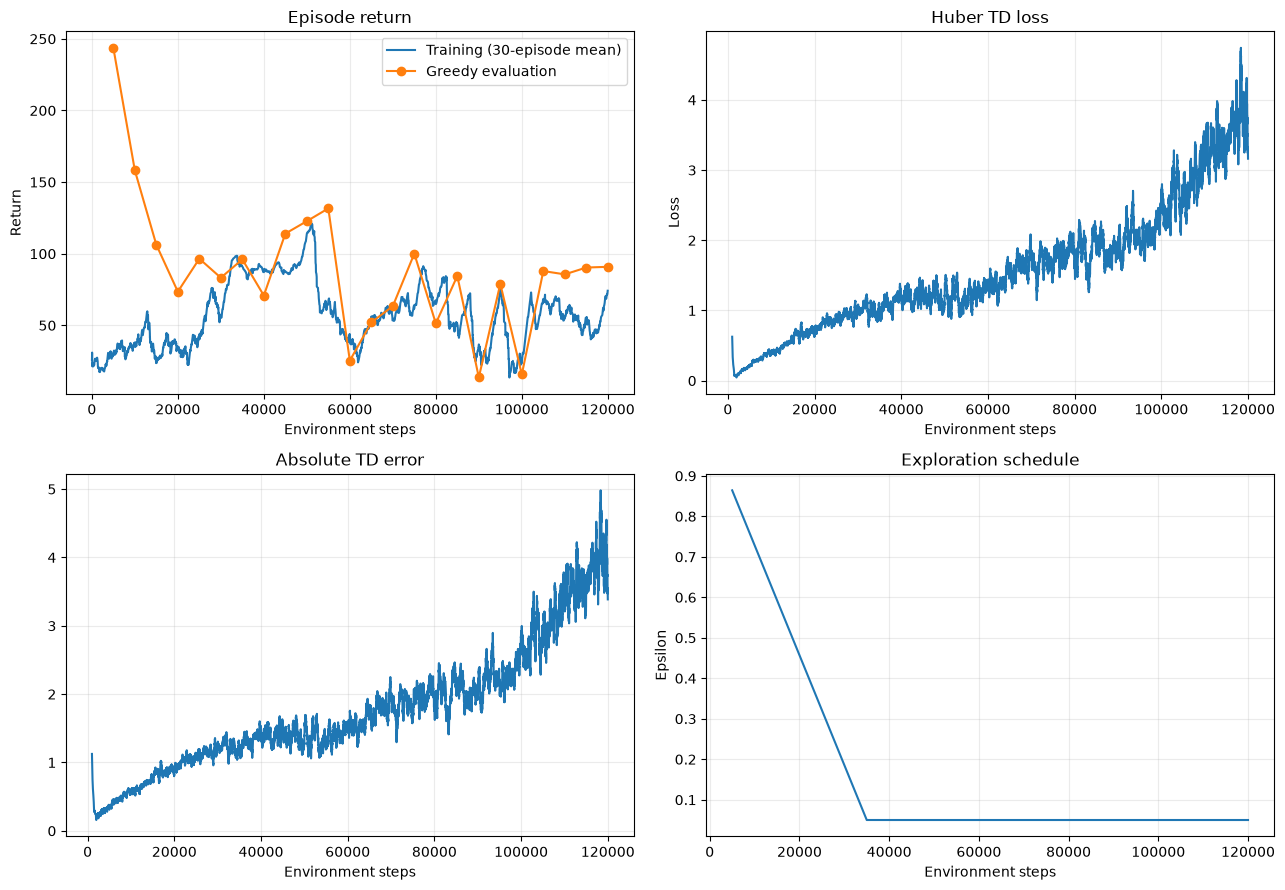

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
ep, upd, ev = logs["episodes"], logs["updates"], logs["evaluation"]
if not ep.empty:
    axes[0, 0].plot(ep["step"], ep["return_"].rolling(30, min_periods=1).mean(),
                    label="Training (30-episode mean)")
axes[0, 0].plot(ev["step"], ev["mean_return"], marker="o",
                label="Greedy evaluation")
axes[0, 0].set(title="Episode return", xlabel="Environment steps", ylabel="Return")
axes[0, 0].legend()
axes[0, 1].plot(upd["step"], upd["loss"].rolling(100, min_periods=1).mean())
axes[0, 1].set(title="Huber TD loss", xlabel="Environment steps", ylabel="Loss")
axes[1, 0].plot(upd["step"], upd["abs_td_error"].rolling(100, min_periods=1).mean())
axes[1, 0].set(title="Absolute TD error", xlabel="Environment steps")
axes[1, 1].plot(ev["step"], ev["epsilon"])
axes[1, 1].set(title="Exploration schedule", xlabel="Environment steps",
               ylabel="Epsilon")
for ax in axes.flat: ax.grid(alpha=.25)
plt.tight_layout()
plt.show()


## 9. Final evaluation: greedy and epsilon-greedy

,policy,mean,median,std,ci_low,ci_high
0,greedy,90.769997,91.0,2.80,90.22,91.30
1,epsilon-greedy,67.470001,86.5,31.82,60.98,73.49


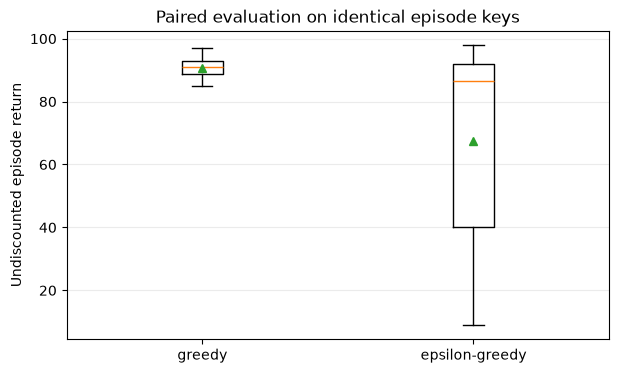

In [10]:
eval_keys = jax.random.split(jax.random.PRNGKey(2026), 100)
rows, final_scores = [], {}
for greedy in (True, False):
    scores = evaluate(params, eval_keys, greedy=greedy)
    label = "greedy" if greedy else "epsilon-greedy"
    final_scores[label] = scores
    lo, hi = bootstrap_ci(scores)
    rows.append(dict(policy=label, mean=scores.mean(), median=np.median(scores),
                     std=scores.std(ddof=1), ci_low=lo, ci_high=hi))
display(pd.DataFrame(rows).round(2))
fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot(list(final_scores.values()), tick_labels=list(final_scores),
           showmeans=True)
ax.set(ylabel="Undiscounted episode return",
       title="Paired evaluation on identical episode keys")
ax.grid(axis="y", alpha=.25)
plt.show()


## 10. Ablation: experience replay and target-network frequency

Ablations share the same initial seed and fixed evaluation keys. For faster iteration, use 60,000 steps; increase to the full baseline budget for publication-quality comparisons.

The no-replay comparison also changes batch size from 64 to 1. This is an intentionally simple demonstration of the stabilizing role of replay, **not a strictly isolated causal estimate**. The target-frequency experiment is controlled except for the changed synchronization interval.


In [13]:
RUN_ABLATIONS = False
if RUN_ABLATIONS:
    ablation_cfg = replace(CFG, total_steps=60_000)
    variants = {
        "baseline": ablation_cfg,
        "no replay": replace(ablation_cfg, use_replay=False),
        "target every 100": replace(ablation_cfg, target_update_frequency=100),
        "target every 2000": replace(ablation_cfg, target_update_frequency=2000),
    }
    ablation_results = {}
    for label, config in variants.items():
        print("\n", label)
        ablation_results[label] = train_dqn(config)
    fig, ax = plt.subplots(figsize=(9, 5))
    for label, (_, result) in ablation_results.items():
        ev = result["evaluation"]
        ax.plot(ev["step"], ev["mean_return"], label=label)
    ax.set(xlabel="Environment steps", ylabel="Greedy evaluation return",
           title="Replay and target-network ablations")
    ax.legend(); ax.grid(alpha=.25)
    plt.show()


## 11. Multi-seed evaluation (optional)

In [14]:
RUN_MULTISEED = False
SEEDS = (0, 1, 2, 3, 4)
if RUN_MULTISEED:
    seed_rows = []
    common_keys = jax.random.split(jax.random.PRNGKey(98765), 100)
    for seed in SEEDS:
        model_params, _ = train_dqn(CFG, seed=seed, verbose=False)
        scores = evaluate(model_params, common_keys)
        seed_rows.append(dict(seed=seed, mean_return=float(scores.mean()),
                              median_return=float(np.median(scores))))
    seed_df = pd.DataFrame(seed_rows)
    display(seed_df.round(2))
    print("Across-seed mean ± SD:",
          seed_df["mean_return"].mean(), "±", seed_df["mean_return"].std(ddof=1))


## 12. Conclusions and next notebook

After running, inspect the baseline's greedy evaluation curve, the TD loss, and the sensitivity to replay and target synchronization. A decreasing TD loss **does not necessarily** imply improved policy performance: the targets move as the policy and target network change.

**Implementation limitations:** this is a single-environment DQN; the outer interaction loop is Python-driven. No prioritized replay, Double DQN, dueling network, n-step returns, or distributional RL are used. Those extensions should not be conflated with original DQN.

**Next: Notebook 06 — Double DQN, Dueling DQN, and Prioritized Experience Replay.**
